In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from cordex2energy.data_processing.load_data import ClimateModelData
from cordex2energy.data_processing.test_climate_data import (
    has_duplicate_coords,
    has_identical_random_timesteps,
    is_time_sorted,
)
from cordex2energy.utils.cdo_commands import cdo_remap, save_cdo_griddes
from cordex2energy.utils.constants import EXTENT_BC, EXTENT_BC_MRRO, EXTENT_CH, REFERENCE_PERIOD, FUTURE_PERIOD, EXTENT_PREVAH
from cordex2energy.utils.utils_xarray import sel_extent

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set({'distributed.worker.memory.target': 0.75})  # Spill to disk at 75% usage
dask.config.set({'distributed.worker.memory.spill': 0.8})   # Start spilling at 80%
dask.config.set({'distributed.worker.memory.pause': 0.9})   # Pause worker at 90%

# MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1

In [5]:
climate_model_chain = "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

bias_corrected_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
)

regridded_dir = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "regridded"
    )

In [7]:
variables_3hr = ["tas", "hurs", "ps", "sfcWind", "rsds"]
variables_day = ["pr", "mrro", "clt", "psl"]
for variable in variables_3hr:
    ds = xr.open_zarr(bias_corrected_dir / "3hr" / f"{variable}.zarr", chunks="auto")
    print(ds.sizes["lat"], ds.sizes["lon"], ds.sizes["time"])

426 710 321193
426 710 321193
426 710 321193
426 710 321193
426 710 321192


In [9]:
ds = xr.open_zarr(bias_corrected_dir / "3hr" / "tas.zarr", chunks="auto")
ds

<xarray.Dataset> Size: 389GB
Dimensions:  (lat: 426, lon: 710, time: 321193)
Coordinates:
  * lat      (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon      (lon) float64 6kB -29.95 -29.85 -29.75 -29.65 ... 40.75 40.85 40.95
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2100-12-31
Data variables:
    tas      (time, lat, lon) float32 389GB dask.array<chunksize=(2920, 128, 128), meta=np.ndarray>
Attributes: (12/28)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/2067855c-322a-44b3-9e5b-d75d...

In [13]:
path_zarr_temp = Path("/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/energy/europe/pv/MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/")
for path in path_zarr_temp.glob("*.zarr"):
    ds = xr.open_zarr(path, chunks="auto")
    print(path.name, ds.sizes["lat"], ds.sizes["lon"], ds.sizes["time"])

pv_MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_1991_2005.zarr 426 460 43800
pv_MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_1991_2020.zarr 426 710 87600
pv_MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_2021_2050.zarr 426 710 87600
pv_MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_2051_2080.zarr 426 710 87600
pv_MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85_2081_2100.zarr 426 710 58392


In [19]:
nb_folders = len(list((
            Path(paths["path_routed_runoff_argon"]) / f"{climate_model_chain}_{climate_scenario}"
        ).glob("*"))
    )

In [22]:
list((
            Path(paths["path_routed_runoff_argon"]) / f"{climate_model_chain}_{climate_scenario}"
        ).glob("*/"))

[PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/1991-1995'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/1996-2000'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2001-2005'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2006-2010'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2011-2015'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2016-2020'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2021-2025'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2026-2030'),
 PosixPath('/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85/2031-

# Verify presence of climate variables

In [ ]:
climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1",
    "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1",
    "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1",
    "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1",
    "MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1"]
climate_scenarios = ["rcp26", "rcp85"]

variables_3hr = ["tas", "hurs", "ps", "sfcWind", "rsds"]
variables_day = ["pr", "mrro", "clt", "psl"]

for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )
        if bias_corrected_dir.exists():
            print(f"Checking {climate_model_chain} - {climate_scenario}")
            for temp_res in ["3hr", "day"]:
                present = sorted([path.stem for path in (bias_corrected_dir / temp_res).glob("*.zarr")])
                expected = variables_3hr if temp_res == "3hr" else variables_day
                missing = set(expected) - set(present)
                print(f"{temp_res}: Missing: {missing}" if missing else 'All variables present')
            print()

In [ ]:
variables_prevah = [
    "huss",
    "hurs",
    "pr",
    "rsds",
    "sfcWind",
    "tas",
    "tas_max",
    "tas_min",
    "clt",
    "psl",
]


for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )
        if bias_corrected_dir.exists():
            print(f"Checking {climate_model_chain} - {climate_scenario}")
            for temp_res in ["day"]:
                present = sorted([path.stem for path in (bias_corrected_dir / temp_res).glob("*.zarr")])
                expected = variables_prevah
                missing = set(expected) - set(present)
                print(f"{temp_res}: {missing if missing else 'All variables present'}")
            print()

In [ ]:
climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"]
climate_scenarios = ["rcp26", "rcp85"]

for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )
        if bias_corrected_dir.exists():
            print(f"Checking {climate_model_chain} - {climate_scenario}")
            for temp_res in ["day"]:
                present = sorted([path.stem for path in (bias_corrected_dir / temp_res).glob("*.zarr")])

                n_vars = len(present)
                if n_vars == 0:
                    print(f"  {temp_res}: no variables found")
                    continue

                ncols = min(3, n_vars)
                nrows = (n_vars + ncols - 1) // ncols

                fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
                if n_vars == 1:
                    axes = np.array([axes])
                axes = axes.flatten()

                for idx, var in enumerate(present):
                    var_path = bias_corrected_dir / temp_res / f"{var}.zarr"
                    ds_var = xr.open_zarr(var_path, chunks="auto")
                    ds_var[var].isel(time=0).plot(ax=axes[idx])
                    axes[idx].set_title(f"{var}")

                # Hide unused subplots
                for idx in range(n_vars, len(axes)):
                    axes[idx].axis('off')

                plt.suptitle(f"{climate_model_chain} - {climate_scenario} - {temp_res}", fontsize=14)
                plt.tight_layout()
                plt.show()

In [ ]:
import datetime

results = []
for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
            / "day"
            / "mrro.zarr"
        )
        if bias_corrected_dir.exists():
            mod_time = bias_corrected_dir.stat().st_mtime
            mod_date = datetime.datetime.fromtimestamp(mod_time)
            results.append((climate_model_chain, climate_scenario, mod_date))

# Sort by modification date
results.sort(key=lambda x: x[2])

# Print sorted results
for model_chain, scenario, mod_date in results:
    print(f"{model_chain} - {scenario}: {mod_date.strftime('%Y-%m-%d %H:%M:%S')}")

In [ ]:
# Plot bias_corrected and regridded mrro datasets side by side
mrro_paths = {}
climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
                        #  "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
                        ]
climate_scenarios = ["rcp26", "rcp85"]
for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        bias_corrected_mrro_path = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
            / "day"
            / "mrro.zarr"
        )
        regridded_mrro_path = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "regridded"
            / "day"
            / "mrro.zarr"
        )

        if bias_corrected_mrro_path.exists() and regridded_mrro_path.exists():
            mrro_paths[(climate_model_chain, climate_scenario)] = {
                'bias_corrected': bias_corrected_mrro_path,
                'regridded': regridded_mrro_path
            }

n_results = len(mrro_paths)

for idx, ((model_chain, scenario), paths_dict) in enumerate(mrro_paths.items()):
    print(f"Plotting {model_chain} - {scenario}")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes = axes.flatten()
    # Plot bias corrected
    date = "2050-05-01"
    ds_regridded = xr.open_zarr(paths_dict['regridded'], chunks="auto")
    nan_mask = ds_regridded["mrro"].sel(time=date).isnull().any(dim="time")
    ds_bias_corrected = xr.open_zarr(paths_dict['bias_corrected'], chunks="auto")

    # Plot regridded
    (ds_regridded["mrro"].sel(time=date) * 86400).plot(ax=axes[1])
    axes[1].set_title(f"{model_chain} - {scenario}\nRegridded")
    # Get vmin and vmax from regridded data
    vmin = float((ds_regridded["mrro"].sel(time=date) * 86400).min().values)
    vmax = float((ds_regridded["mrro"].sel(time=date) * 86400).max().values)

    # Replot bias corrected with same color scale
    axes[0].clear()
    ds_bias_corrected["mrro"].sel(time=date).where(~nan_mask).plot(ax=axes[0], vmin=vmin, vmax=vmax)
    axes[0].set_title(f"{model_chain} - {scenario}\nBias Corrected")

    plt.tight_layout()
    plt.show()

In [ ]:
sel_extent(xr.open_zarr(mrro_paths[('MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1', 'rcp26')]["regridded"]).isel(time=1000), extent=EXTENT_CH).mrro.plot()

In [ ]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp26"

variables_huss = ["hurs", "ps", "tas"]

bias_corrected_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
)
if bias_corrected_dir.exists():
    for var in variables_huss:
        print(f"Checking {climate_model_chain} - {climate_scenario} - {var}")
        ds = xr.open_zarr(bias_corrected_dir / "day" / f"{var}.zarr", chunks="auto")
        print(ds.time.values[0], ds.time.values[-1])

In [ ]:
climate_model_chains = [
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1",
    "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1",
    "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1",
    "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1",
    "MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1"
]
climate_scenarios = ["rcp26", "rcp85"]

variables_3hr = ["tas", "hurs", "ps", "sfcWind", "rsds"]
variables_day = ["pr", "mrro", "clt", "psl"]

# Mapping of variables to their reference variables and height
variable_mapping = {
    "tas": ("2t", "3hr", 2),
    "hurs": ("2r", "3hr", 2),
    "ps": ("sp", "3hr", None),
    "sfcWind": ("10si", "3hr", 10),
    "rsds": ("ssrd", "3hr", None),
    "pr": ("tp", "day", None),
    "mrro": ("ro", "day", None),
    "clt": ("tcc", "day", None),
    "psl": ("msl", "day", None),
}

# Configuration
paths_file = "../../paths_so4.json"
nr_processes = 35
memory_limit = "auto"

print("=" * 80)
print("CHECKING FOR MISSING BIAS-CORRECTED VARIABLES")
print("=" * 80)

# Collect missing variables
missing_jobs = []

for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )
        if bias_corrected_dir.exists():
            print(f"\nChecking {climate_model_chain} - {climate_scenario}")
            for temp_res in ["3hr", "day"]:
                present = sorted([path.stem for path in (bias_corrected_dir / temp_res).glob("*.zarr")])
                expected = variables_3hr if temp_res == "3hr" else variables_day
                missing = set(expected) - set(present)

                if missing:
                    print(f"  {temp_res}: Missing {missing}")
                    for var in missing:
                        if var in variable_mapping:
                            var_ref, temp_res_var, height_ref = variable_mapping[var]
                            missing_jobs.append({
                                "model": climate_model_chain,
                                "scenario": climate_scenario,
                                "variable": var,
                                "variable_ref": var_ref,
                                "temp_res": temp_res_var,
                                "height_ref": height_ref
                            })
                else:
                    print(f"  {temp_res}: All variables present")

In [ ]:
climate_model_chains = [
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
    # "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    # "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    # "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1",
    # "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1",
    # "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1",
    # "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    # "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1",
    # "MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1"
]
climate_scenarios = ["rcp26", "rcp85"]

variables_3hr = ["tas", "hurs", "ps", "sfcWind", "rsds"]
variables_day = ["pr", "mrro", "clt", "psl"]

# Mapping of variables to their reference variables and height
variable_mapping = {
    "tas": ("2t", "3hr", 2),
    "hurs": ("2r", "3hr", 2),
    "ps": ("sp", "3hr", None),
    "sfcWind": ("10si", "3hr", 10),
    "rsds": ("ssrd", "3hr", None),
    "pr": ("tp", "day", None),
    "mrro": ("ro", "day", None),
    "clt": ("tcc", "day", None),
    "psl": ("msl", "day", None),
}

# Configuration
paths_file = "../../paths_so4.json"
nr_processes = 35
memory_limit = "auto"

print("=" * 80)
print("CHECKING FOR MISSING BIAS-CORRECTED VARIABLES")
print("=" * 80)

# Collect missing variables
missing_jobs = []

for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        regridded_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "regridded"
        )
        if regridded_dir.exists():
            print(f"\nChecking {climate_model_chain} - {climate_scenario}")
            for temp_res in ["3hr", "day"]:
                present = sorted([path.stem for path in (regridded_dir / temp_res).glob("*.zarr")])
                expected = variables_3hr if temp_res == "3hr" else variables_day
                missing = set(expected) - set(present)
                if missing:
                    print(f"  {temp_res}: Missing {missing}")
                # Plot all variables in subplots
                n_vars = len(present)
                if n_vars > 0:
                    ncols = min(3, n_vars)
                    nrows = (n_vars + ncols - 1) // ncols

                    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
                    if n_vars == 1:
                        axes = np.array([axes])
                    axes = axes.flatten()

                    for idx, var in enumerate(present):
                        var_path = regridded_dir / temp_res / f"{var}.zarr"
                        ds_var = xr.open_zarr(var_path, chunks="auto")
                        ds_var[var].isel(time=0).plot(ax=axes[idx])
                        axes[idx].set_title(f"{var}")

                    # Hide unused subplots
                    for idx in range(n_vars, len(axes)):
                        axes[idx].axis('off')

                    plt.suptitle(f"{climate_model_chain} - {climate_scenario} - {temp_res}", fontsize=14)
                    plt.tight_layout()
                    plt.show()

In [ ]:
import numcodecs
import zarr
import xarray as xr
from numcodecs import blosc

print(f"numcodecs version: {numcodecs.__version__}")
print(f"zarr version: {zarr.__version__}")
print(f"xarray version: {xr.__version__}")

In [ ]:
!conda list | grep zstd

In [ ]:
!conda list | grep blosc

In [ ]:
from numcodecs.blosc import Blosc
import json

meta = json.load(open("/landclim_nobackup/FTP/yhaddad/wind_ch/wind_power/wind_power_rcp85.zarr/E-92_2350/.zarray"))
print(meta["compressor"])
print(Blosc().get_config())

# Precipitation data

In [ ]:
ds_tp = sel_extent(xr.open_zarr(path_data_processed / "cerra_processed" / "regridded" / "tp.zarr", chunks="auto"), extent=EXTENT_PREVAH).sel(time=slice("1991", "2020"))

In [ ]:
with ProgressBar(dt=1):
    ds_tp_max = ds_tp.max(dim="time").compute()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5), subplot_kw={'projection': ccrs.PlateCarree()})
ds_tp_max.tp.plot(ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False)
ax.coastlines(resolution='10m', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
# Create shared colorbar with correct vmin/vmax
cbar = fig.colorbar(ax.collections[0], ax=ax, orientation='horizontal', pad=0.05, shrink=0.8, label='Maximum Daily Total Precipitation [kg m-2]')
plt.title("CERRA - Maximum Daily Total Precipitation (1991-2020)", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
climate_model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1",
    "CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1",
    "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
    "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1",
    "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    "MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1"
    ]
climate_scenario = "rcp85"

In [ ]:
# First pass: compute all max values to get vmin/vmax
print("Computing max values for all models...")
ds_max_list = []
for climate_model_chain in climate_model_chains:
    bias_corrected_dir = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
    )
    ds = sel_extent(xr.open_zarr(bias_corrected_dir.parent / "regridded" / "day" / "pr.zarr", chunks="auto"), extent=EXTENT_PREVAH)
    with ProgressBar(dt=0.5):
        ds_max = ds.pr.max(dim=["time"]).compute()
    ds_max_list.append(ds_max)

In [ ]:
# Compute global vmin and vmax
vmin = min([float(ds_max.min().values) for ds_max in ds_max_list])
vmax = max([float(ds_max.max().values) for ds_max in ds_max_list])
print(f"Global vmin: {vmin}, vmax: {vmax}")

# Second pass: plot with consistent colorbar
fig, axs = plt.subplots(3, 3, figsize=(24, 10), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()

for idx, (climate_model_chain, ds_max) in enumerate(zip(climate_model_chains, ds_max_list)):
    ds_max.plot(ax=axs[idx], transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax, add_colorbar=False)
    axs[idx].set_title(f"{climate_model_chain} - {climate_scenario}")
    axs[idx].text(0.02, 0.98, f'range: [{float(ds_max.min().values):.6f}, {float(ds_max.max().values):.6f}]',
                  transform=axs[idx].transAxes, fontsize=8, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    axs[idx].coastlines(resolution='10m', linewidth=0.8)
    axs[idx].add_feature(cfeature.BORDERS, linewidth=0.8)

fig.suptitle(f"Maximum Daily Precipitation Rate for Original Climate Model data - {climate_scenario}", fontsize=14, y=0.95)
# Create shared colorbar with correct vmin/vmax
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05, shrink=0.3, label='Maximum Daily Precipitation Rate [kg m-2 s-1]')
# plt.tight_layout()
plt.show()

In [ ]:
# First pass: compute all max values to get vmin/vmax
print("Computing max values for all models...")
ds_bc_max_list = []
for climate_model_chain in climate_model_chains:
    bias_corrected_dir = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
    )
    ds = sel_extent(xr.open_zarr(bias_corrected_dir / "day" / "pr.zarr", chunks="auto"), extent=EXTENT_PREVAH)
    with ProgressBar(dt=0.5):
        ds_max = ds.pr.max(dim=["time"]).compute()
    ds_bc_max_list.append(ds_max)

In [ ]:
# Compute global vmin and vmax
vmin = min([float(ds_max.min().values) for ds_max in ds_bc_max_list])
vmax = max([float(ds_max.max().values) for ds_max in ds_bc_max_list])
print(f"Global vmin: {vmin}, vmax: {vmax}")

# Second pass: plot with consistent colorbar
fig, axs = plt.subplots(3, 3, figsize=(24, 10), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()

for idx, (climate_model_chain, ds_max) in enumerate(zip(climate_model_chains, ds_bc_max_list)):
    ds_max.plot(ax=axs[idx], transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax, add_colorbar=False)
    axs[idx].set_title(f"{climate_model_chain} - {climate_scenario}")
    axs[idx].text(0.02, 0.98, f'range: [{float(ds_max.min().values):.6f}, {float(ds_max.max().values):.6f}]',
                  transform=axs[idx].transAxes, fontsize=8, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    axs[idx].coastlines(resolution='10m', linewidth=0.8)
    axs[idx].add_feature(cfeature.BORDERS, linewidth=0.8)

fig.suptitle(f"Maximum Daily Total Precipitation for Bias-Corrected Climate Model data - {climate_scenario}", fontsize=14, y=0.95)
# Create shared colorbar with correct vmin/vmax
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05, shrink=0.3, label='Maximum Daily Total Precipitation [mm/day]')
# plt.tight_layout()
plt.show()

In [ ]:
from matplotlib.colors import TwoSlopeNorm

ds_bc_max_ratio_cerra_list = [ds_max/ds_tp_max.tp for ds_max in ds_bc_max_list]

# Compute global vmin and vmax
vmin = min([float(ds_max.min().values) for ds_max in ds_bc_max_ratio_cerra_list])
vmax = max([float(ds_max.max().values) for ds_max in ds_bc_max_ratio_cerra_list])

# Create normalization centered at 1
norm = TwoSlopeNorm(vmin=0, vcenter=1.0, vmax=5)
print(f"Global vmin: {vmin}, vcenter: 1.0, vmax: {vmax}")

# Second pass: plot with consistent colorbar
fig, axs = plt.subplots(3, 3, figsize=(24, 10), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()

for idx, (climate_model_chain, ds_max) in enumerate(zip(climate_model_chains, ds_bc_max_ratio_cerra_list)):
    ds_max.plot(ax=axs[idx], transform=ccrs.PlateCarree(), norm=norm, cmap='RdBu_r', add_colorbar=False)
    axs[idx].set_title(f"{climate_model_chain} - {climate_scenario}")
    axs[idx].text(0.02, 0.98, f'range: [{float(ds_max.min().values):.6f}, {float(ds_max.max().values):.6f}]',
                  transform=axs[idx].transAxes, fontsize=8, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    axs[idx].coastlines(resolution='10m', linewidth=0.8)
    axs[idx].add_feature(cfeature.BORDERS, linewidth=0.8)

fig.suptitle(f"Per-grid cell Multiplication factor of Maximum Daily Total Precipitation for\nBias-Corrected Climate Model data - {climate_scenario}, with respect to CERRA", fontsize=14, y=0.95)
# Create shared colorbar with correct vmin/vmax
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05, shrink=0.3, label='Multiplication Factor [-]')
# plt.tight_layout()
plt.show()

In [ ]:
ds_bc_max_ratio_cerra_list = [ds_max/ds_tp_max.tp.max() for ds_max in ds_bc_max_list]

# Compute global vmin and vmax
vmin = min([float(ds_max.min().values) for ds_max in ds_bc_max_ratio_cerra_list])
vmax = max([float(ds_max.max().values) for ds_max in ds_bc_max_ratio_cerra_list])
print(f"Global vmin: {vmin}, vmax: {vmax}")


# Create normalization centered at 1
norm = TwoSlopeNorm(vmin=0, vcenter=1.0, vmax=vmax)
# Second pass: plot with consistent colorbar
fig, axs = plt.subplots(3, 3, figsize=(24, 10), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()

for idx, (climate_model_chain, ds_max) in enumerate(zip(climate_model_chains, ds_bc_max_ratio_cerra_list)):
    ds_max.plot(ax=axs[idx], transform=ccrs.PlateCarree(), norm=norm, cmap='RdBu_r', add_colorbar=False)
    axs[idx].set_title(f"{climate_model_chain} - {climate_scenario}")
    axs[idx].text(0.02, 0.98, f'range: [{float(ds_max.min().values):.6f}, {float(ds_max.max().values):.6f}]',
                  transform=axs[idx].transAxes, fontsize=8, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    axs[idx].coastlines(resolution='10m', linewidth=0.8)
    axs[idx].add_feature(cfeature.BORDERS, linewidth=0.8)

fig.suptitle(f"Multiplication factor of Maximum Daily Total Precipitation for\nBias-Corrected Climate Model data - {climate_scenario}, with respect to CERRA absolute maximum", fontsize=14, y=0.95)
# Create shared colorbar with correct vmin/vmax
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05, shrink=0.3, label='Multiplication Factor [-]')
# plt.tight_layout()
plt.show()

In [ ]:
# Compute frequency of exceeding 300mm/day threshold for bias-corrected precipitation
threshold = 300  # mm/day
ds_bc_exceedance_list = []

for climate_model_chain in climate_model_chains:
    print(f"Processing {climate_model_chain} - {climate_scenario}")
    bias_corrected_dir = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
    )
    ds = sel_extent(xr.open_zarr(bias_corrected_dir / "day" / "pr.zarr", chunks="auto"), extent=EXTENT_PREVAH)

    with ProgressBar(dt=0.5):
        # Count number of times each grid cell exceeds the threshold
        exceedance_count = (ds.pr > threshold).sum(dim="time").compute()

    ds_bc_exceedance_list.append(exceedance_count)

In [ ]:
# Plot frequency of exceeding 300 mm/day threshold with consistent colorbar
# Compute global vmin and vmax
vmin = min([float(exceedance.min().values) for exceedance in ds_bc_exceedance_list])
vmax = max([float(exceedance.max().values) for exceedance in ds_bc_exceedance_list])
print(f"Global vmin: {vmin}, vmax: {vmax}")

# Create plot with consistent colorbar
fig, axs = plt.subplots(3, 3, figsize=(24, 10), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()

for idx, (climate_model_chain, exceedance) in enumerate(zip(climate_model_chains, ds_bc_exceedance_list)):
    exceedance.plot(ax=axs[idx], transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax,
                    add_colorbar=False, cmap='YlOrRd')
    axs[idx].set_title(f"{climate_model_chain} - {climate_scenario}")
    axs[idx].text(0.02, 0.98, f'range: [{int(exceedance.min().values)}, {int(exceedance.max().values)}]',
                  transform=axs[idx].transAxes, fontsize=8, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    axs[idx].coastlines(resolution='10m', linewidth=0.8)
    axs[idx].add_feature(cfeature.BORDERS, linewidth=0.8)

fig.suptitle(f"Frequency of Exceeding {threshold} mm/day for Bias-Corrected Precipitation - {climate_scenario}",
             fontsize=14, y=0.95)
# Create shared colorbar
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05,
                    shrink=0.3, label=f'Number of Days Exceeding {threshold} mm/day')
plt.show()

In [ ]:
# Compute frequency of exceeding 150mm/day threshold for bias-corrected precipitation
threshold = 150  # mm/day
ds_bc_exceedance_150_list = []

for climate_model_chain in climate_model_chains:
    print(f"Processing {climate_model_chain} - {climate_scenario}")
    bias_corrected_dir = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
    )
    ds = sel_extent(xr.open_zarr(bias_corrected_dir / "day" / "pr.zarr", chunks="auto"), extent=EXTENT_PREVAH)

    with ProgressBar(dt=0.5):
        # Count number of times each grid cell exceeds the threshold
        exceedance_count = (ds.pr > threshold).sum(dim="time").compute()

    ds_bc_exceedance_150_list.append(exceedance_count)

In [ ]:
# Plot frequency of exceeding 300 mm/day threshold with consistent colorbar
# Compute global vmin and vmax
vmin = min([float(exceedance.min().values) for exceedance in ds_bc_exceedance_150_list])
vmax = max([float(exceedance.max().values) for exceedance in ds_bc_exceedance_150_list])
print(f"Global vmin: {vmin}, vmax: {vmax}")

# Create plot with consistent colorbar
fig, axs = plt.subplots(3, 3, figsize=(24, 10), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()

for idx, (climate_model_chain, exceedance) in enumerate(zip(climate_model_chains, ds_bc_exceedance_150_list)):
    exceedance.plot(ax=axs[idx], transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax,
                    add_colorbar=False, cmap='YlOrRd')
    axs[idx].set_title(f"{climate_model_chain} - {climate_scenario}")
    axs[idx].text(0.02, 0.98, f'range: [{int(exceedance.min().values)}, {int(exceedance.max().values)}]',
                  transform=axs[idx].transAxes, fontsize=8, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    axs[idx].coastlines(resolution='10m', linewidth=0.8)
    axs[idx].add_feature(cfeature.BORDERS, linewidth=0.8)

fig.suptitle(f"Frequency of Exceeding {threshold} mm/day for Bias-Corrected Precipitation - {climate_scenario}",
             fontsize=14, y=0.95)
# Create shared colorbar
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05,
                    shrink=0.3, label=f'Number of Days Exceeding {threshold} mm/day')
plt.show()

# MOHC-MOHC and MOHC-ICHEC

In [5]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp85"

In [8]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp85"
longest_time = []
print(f"Processing {climate_model_chain} - {climate_scenario}")
bias_corrected_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
)

ds = sel_extent(xr.open_zarr(bias_corrected_dir.parent / "regridded" / "3hr" / "hurs.zarr", chunks="auto"), extent=EXTENT_PREVAH)
ds_bc = sel_extent(xr.open_zarr(bias_corrected_dir / "3hr" / "hurs.zarr", chunks="auto"), extent=EXTENT_PREVAH)

Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp85


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ds_bc.sel(time="2017-10-09").pr.plot(ax=ax[0])
(ds.sel(time="2017-10-09").pr.plot(ax=ax[1])
plt.show()

In [ ]:
ds_tp = sel_extent(xr.open_zarr(path_data_processed / "cerra_processed" / "regridded" / "tp.zarr", chunks="auto"), extent=EXTENT_PREVAH)

ds_tp.sel(time="2017-10-07").tp.plot()

In [ ]:
with ProgressBar(dt=5):
    ds_max = ds.pr.max(dim=["time"]).compute()
    ds_bc_max = ds_bc.pr.max(dim=["time"]).compute()

In [ ]:
with ProgressBar(dt=5):
    ds_tp_max = ds_tp.tp.max(dim=["time"]).compute()

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6), sharey=True, subplot_kw={'projection': ccrs.PlateCarree()})
# (ds_max * 86400).plot(ax=axs[0], transform=ccrs.PlateCarree())
# ds_bc_max.plot(ax=axs[1], transform=ccrs.PlateCarree())
# ds_tp_max.plot(ax=axs[2], transform=ccrs.PlateCarree())
# for ax in axs:
#     ax.coastlines(resolution='10m', linewidth=0.8)
#     ax.add_feature(cfeature.BORDERS, linewidth=0.8)

# Remove individual colorbars and create one shared colorbar
for ax in axs:
    if ax.collections:
        ax.collections[0].colorbar.remove()

# Create shared colorbar
vmin = min((ds_max * 86400).min().values, ds_bc_max.min().values, ds_tp_max.min().values)
vmax = max((ds_max * 86400).max().values, ds_bc_max.max().values, ds_tp_max.max().values)

# Replot with shared limits
axs[0].clear()
axs[1].clear()
axs[2].clear()

(ds_max * 86400).plot(ax=axs[0], transform=ccrs.PlateCarree(), vmin=vmin, vmax=600, add_colorbar=False)
ds_bc_max.plot(ax=axs[1], transform=ccrs.PlateCarree(), vmin=vmin, vmax=600, add_colorbar=False)
im = ds_tp_max.plot(ax=axs[2], transform=ccrs.PlateCarree(), vmin=vmin, vmax=600, add_colorbar=False)

for ax in axs:
    ax.coastlines(resolution='10m', linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
cbar = fig.colorbar(axs[0].collections[0], ax=axs, orientation='horizontal', pad=0.05, shrink=0.2)
cbar.set_label('Maximum Daily Precipitation [mm/day]')
# plt.tight_layout()
plt.show()


In [ ]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
longest_time = []
print(f"Processing {climate_model_chain} - {climate_scenario}")
bias_corrected_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "bias_corrected"
)

ds_cnrm = sel_extent(xr.open_zarr(bias_corrected_dir.parent / "regridded" / "day" / "pr.zarr", chunks="auto"), extent=EXTENT_PREVAH)

In [ ]:
ds_pr_max = ds.pr.max(dim=["time"]).compute()
ds_cnrm_pr_max = ds_cnrm.pr.max(dim=["time"]).compute()

In [ ]:
ds_pr_max.plot()

In [ ]:
ds_cnrm_pr_max.plot()

In [ ]:
climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1", "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"]
climate_scenarios = ["rcp26", "rcp85"]

for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Checking {climate_model_chain} - {climate_scenario}")
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )

        for temp_res in ["3hr", "day"]:
            present = sorted([path.stem for path in (bias_corrected_dir / temp_res).glob("*.zarr")])
            print(f"{temp_res}: {present}")

In [ ]:
ds_tcc = sel_extent(xr.open_zarr(path_data_processed / "cerra_processed" / "regridded" / "tcc.zarr", chunks="auto"), extent=EXTENT_PREVAH)
# Find timesteps with null values
null_timesteps = ds_tcc["tcc"].isnull().any(dim=["lat", "lon"]).compute()
timesteps_with_nulls = ds_tcc.time[null_timesteps]

if len(timesteps_with_nulls) > 0:
    print(timesteps_with_nulls)
    # Plot the first timestep with null values
    first_null_timestep = timesteps_with_nulls[0].values
    print(f"Plotting timestep with null values: {first_null_timestep}")
    ds_tcc["tcc"].sel(time=first_null_timestep).plot()
    plt.title(f"CERRA - tcc at {first_null_timestep}")
    plt.show()
else:
    print("No timesteps with null values found")

In [ ]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp26"
longest_time = []
print(f"Processing {climate_model_chain} - {climate_scenario}")
bias_corrected_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

ds = sel_extent(xr.open_zarr(bias_corrected_dir / "day" / "clt.zarr", chunks="auto"), extent=EXTENT_PREVAH)

In [ ]:
ds_tcc.isel(time=100).tcc.plot()

In [ ]:
ds.isel(time=10000).clt.plot()

Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp26
[########################################] | 100% Completed | 250.23 s
No timesteps with null values found
Processing MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 - rcp85
[########################################] | 100% Completed | 198.17 s
<xarray.DataArray 'time' (time: 2)> Size: 16B
array(['1995-12-31T06:00:00.000000000', '2006-12-31T12:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 16B 1995-12-31T06:00:00 2006-12-31T12:00:00
Attributes:
    axis:           T
    long_name:      time
    standard_name:  time
Number of timesteps with null values: 2
Plotting timestep with null values: 1995-12-31T06:00:00.000000000


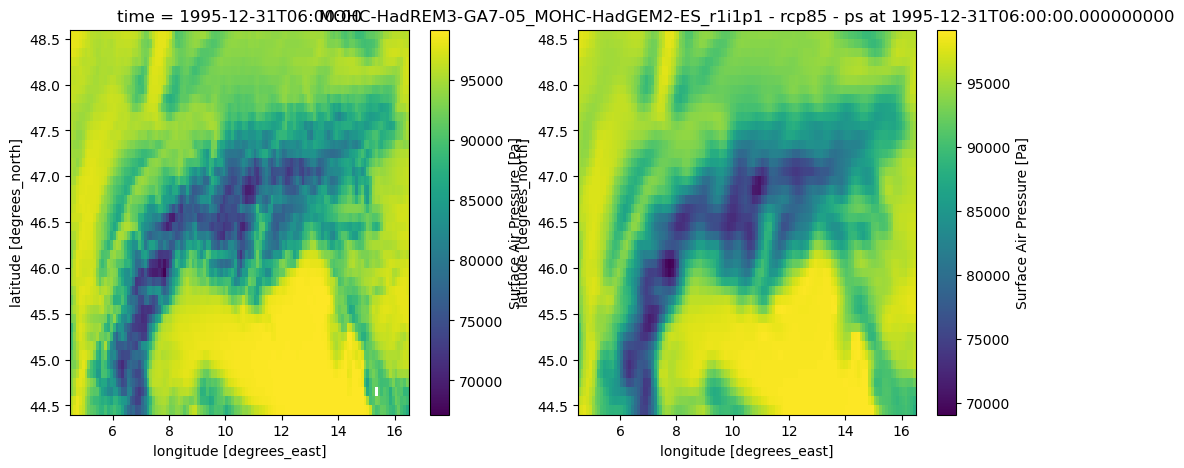

In [16]:
climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1", "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"]
climate_scenarios = ["rcp26", "rcp85"]

climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"]
climate_scenarios = ["rcp26", "rcp85"]

longest_time = []
time_res = "3hr"
var = "ps"
extent = EXTENT_PREVAH
for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}")
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )

        ds = sel_extent(xr.open_zarr(bias_corrected_dir / time_res / f"{var}.zarr", chunks="auto"), extent=extent)
        with ProgressBar(dt=1):
            null_timesteps = ds[var].isnull().any(dim=["lat", "lon"]).compute()
        timesteps_with_nulls = ds.time[null_timesteps]
        if len(timesteps_with_nulls) > 0:
            print(timesteps_with_nulls)
            print(f"Number of timesteps with null values: {len(timesteps_with_nulls)}")
            # Plot the first timestep with null values
            first_null_timestep = timesteps_with_nulls[0].values
            print(f"Plotting timestep with null values: {first_null_timestep}")
            fig, ax = plt.subplots(1, 2, figsize=(12, 5))
            ds[var].sel(time=first_null_timestep).plot(ax=ax[0])
            ds_regridded = sel_extent(xr.open_zarr(
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / time_res
                / f"{var}.zarr", chunks="auto"), extent=extent)
            ds_regridded[var].sel(time=first_null_timestep).plot(ax=ax[1])
            plt.title(f"{climate_model_chain} - {climate_scenario} - {var} at {first_null_timestep}")
            plt.show()
        else:
            print("No timesteps with null values found")

In [15]:
np.unique([pd.Timestamp(time).hour for time in timesteps_with_nulls.values])

array([0])

In [19]:
ds_hurs = sel_extent(xr.open_zarr(bias_corrected_dir / time_res / f"hurs.zarr", chunks="auto"), extent=extent)

In [22]:
ds_hurs_regridded = sel_extent(xr.open_zarr(
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / time_res
                / f"hurs.zarr", chunks="auto"), extent=extent)

In [20]:
ds_hurs

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 318185, lat: 42, lon: 120)
Coordinates:
  * lat      (lat) float64 336B 44.45 44.55 44.65 44.75 ... 48.35 48.45 48.55
  * lon      (lon) float64 960B 4.55 4.65 4.75 4.85 ... 16.15 16.25 16.35 16.45
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-20
Data variables:
    hurs     (time, lat, lon) float32 6GB dask.array<chunksize=(2920, 42, 39), meta=np.ndarray>
Attributes: (12/27)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    NCO:                            4.7.3
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v1
    reference_period:               1991 - 2020
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/1ff2c929-ff09-48d2-ba8d-40fe...

In [ ]:
ds_hurs_regridded.mean(dim=["lat", "lon"]).groupby("time.year").mean(dim="time")

<bound method Mapping.values of <xarray.Dataset> Size: 2kB
Dimensions:  (year: 149)
Coordinates:
    height   float64 8B ...
  * year     (year) int64 1kB 1951 1952 1953 1954 1955 ... 2096 2097 2098 2099
Data variables:
    hurs     (year) float32 596B dask.array<chunksize=(149,), meta=np.ndarray>>

In [ ]:
timesteps = ['1991-02-06T12:00:00.000000000', '1992-11-27T12:00:00.000000000',
       '1994-05-10T12:00:00.000000000', '1995-01-01T12:00:00.000000000',
       '1996-06-01T12:00:00.000000000', '1997-11-28T12:00:00.000000000',
       '1997-12-10T12:00:00.000000000', '1998-06-14T12:00:00.000000000',
       '1999-01-01T12:00:00.000000000', '1999-12-10T12:00:00.000000000',
       '2000-01-01T12:00:00.000000000', '2000-01-31T12:00:00.000000000',
       '2001-11-28T12:00:00.000000000', '2005-05-10T12:00:00.000000000',
       '2008-08-31T12:00:00.000000000', '2011-05-10T12:00:00.000000000',
       '2017-06-14T12:00:00.000000000', '2019-05-10T12:00:00.000000000',
       '2025-06-14T12:00:00.000000000', '2032-11-27T12:00:00.000000000',
       '2033-06-14T12:00:00.000000000', '2033-09-01T12:00:00.000000000',
       '2039-06-14T12:00:00.000000000', '2041-06-04T12:00:00.000000000',
       '2044-08-31T12:00:00.000000000', '2045-03-26T12:00:00.000000000',
       '2045-09-11T12:00:00.000000000', '2048-01-01T12:00:00.000000000',
       '2050-09-01T12:00:00.000000000', '2050-11-28T12:00:00.000000000',
       '2062-01-01T12:00:00.000000000', '2065-05-10T12:00:00.000000000',
       '2077-06-14T12:00:00.000000000', '2081-10-25T12:00:00.000000000',
       '2088-11-27T12:00:00.000000000', '2092-03-25T12:00:00.000000000',
       '2095-09-01T12:00:00.000000000', '2097-12-10T12:00:00.000000000',
       '2099-09-01T12:00:00.000000000']

ds_regridded = sel_extent(xr.open_zarr(
       path_data_processed
       / "cordex_processed"
       / f"{climate_model_chain}_{climate_scenario}"
       / "regridded"
       / "day"
       / f"{var}.zarr", chunks="auto"), extent=EXTENT_BC)
for null_timestep in timesteps[:5]:
    print(f"Processing timestep: {null_timestep}")
    first_null_timestep = np.datetime64(null_timestep)
    fig, ax = plt.subplots(1, 3, figsize=(12, 5))
    ds_sel = ds[var].sel(time=first_null_timestep)
    ds_sel.plot(ax=ax[0])
    ds_sel.where(ds_sel.isnull()).plot(ax=ax[1])
    ds_regridded[var].sel(time=first_null_timestep).plot(ax=ax[2])
    plt.title(f"{climate_model_chain} - {climate_scenario} - {var} at {first_null_timestep}")
    plt.show()

In [ ]:
xr.open_dataset(list(Path("/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26/temp/mrro/blocks/").glob("*.nc"))[0]).mrro.isel(time=100).plot()

In [ ]:
"hurs_EUR-11_MOHC-HadGEM2-ES_rcp85_r1i1p1_MOHC-HadREM3-GA7-05_v1_day_20810101-20851230.nc".split("-")[-1][:4]

In [ ]:
climate_model_chains = ["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1", "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"]
climate_scenarios = ["rcp26", "rcp85"]
longest_time = []
for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Processing {climate_model_chain} - {climate_scenario}")
        bias_corrected_dir = (
            path_data_processed
            / "cordex_processed"
            / f"{climate_model_chain}_{climate_scenario}"
            / "bias_corrected"
        )

        for temp_res in ["day"]:
            temp_res_dir = bias_corrected_dir / temp_res
            if not temp_res_dir.exists():
                print(f"  {temp_res}: directory does not exist")
                continue

            zarr_files = sorted(temp_res_dir.glob("*.zarr"))
            if not zarr_files:
                print(f"  {temp_res}: no zarr files found")
                continue

            print(f"  {temp_res}: found {len(zarr_files)} files")

            # Create subplots for all variables
            n_vars = len(zarr_files)
            ncols = min(3, n_vars)
            nrows = (n_vars + ncols - 1) // ncols

            fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
            if n_vars == 1:
                axes = np.array([axes])
            axes = axes.flatten()

            for idx, zarr_file in enumerate(zarr_files):
                ds_temp = sel_extent(xr.open_zarr(zarr_file, chunks="auto"), extent=EXTENT_PREVAH)
                var_name = list(ds_temp.data_vars)[0]

                # Plot first timestep
                timestep=0 if var_name != "rsds" else 4
                ds_temp[var_name].sel(time="1991-01-01").plot(ax=axes[idx])
                axes[idx].set_title(f"{var_name} - first timestep")

            # Hide unused subplots
            for idx in range(n_vars, len(axes)):
                axes[idx].axis('off')

            plt.suptitle(f"{climate_model_chain} - {climate_scenario} - {temp_res}", fontsize=14)
            plt.tight_layout()
            plt.show()

In [ ]:
temp_postprocessed_mrro = path_data_temporary / "cordex_processed"
for climate_model_chain in climate_model_chains:
    for climate_scenario in climate_scenarios:
        print(f"Checking MRRO {climate_model_chain} - {climate_scenario}")
        bias_corrected_dir = (
            temp_postprocessed_mrro
            / f"{climate_model_chain}_{climate_scenario}"
            / "temp"
            / "mrro"
            / "blocks"
        )
        files = sorted(bias_corrected_dir.glob("*.nc"))
        ds = xr.open_dataset(files[0], chunks="auto")
        ds["mrro"].isel(time=0).plot()
        plt.title(f"MRRO - {climate_model_chain} - {climate_scenario}")
        plt.show()

# CERRA

In [ ]:
import re
with open("../../paths_so4.json") as f:
    paths = json.load(f)

path_data_processed = Path(paths["path_data_processed"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])

def _extract_year(path):
    m = re.search(r'(\d{4})', path.name)
    return int(m.group(1)) if m else None

sro_files = sorted((path_data_cerra_land / "original" / "sro").glob("*.nc"))
perc_files = sorted((path_data_cerra_land / "original" / "perc").glob("*.nc"))

sro_cerra_path = []
for p in sro_files:
    year = _extract_year(p)
    if year is not None and 2004 <= year <= 2010:
        sro_cerra_path.append(p)

perc_cerra_path = []
for p in perc_files:
    year = _extract_year(p)
    if year is not None and 2004 <= year <= 2010:
        perc_cerra_path.append(p)
grid_path = path_data_processed / "climate_grids" / "grid_cerra_griddes.txt"

ro_cerra_path = path_data_processed / "cerra_processed" / "ro"
ro_cerra_path.mkdir(parents=True, exist_ok=True)

In [ ]:
np.unique(xr.open_zarr(path_data_processed / "cerra_processed" / "regridded" / "msl.zarr").time.dt.year.values)

In [ ]:
cerra_path = Path(paths["path_data_cerra"]) / "processed" / "v1" / "msl" / "day" / "native"
for path in cerra_path.glob("*.nc"):
    ds = xr.open_dataset(path)
    print(len(ds["time"]), ds["time"].values[0], ds["time"].values[-1])

In [ ]:
for sim_path in sorted(list((path_data_processed / "cerra_processed" / "temp" / "msl").glob("*.nc"))):
    ds = xr.open_dataset(sim_path)
    print(len(ds["time"]), ds["time"].values[0], ds["time"].values[-1])
    modified = False
    has_duplicates = has_duplicate_coords(ds)
    if any(has_duplicates.values()):
        modified = True
        for dim, has_dup in has_duplicates.items():
            if has_dup:
                print(f"  Dropping duplicate coordinates along {dim} dimension.")
                ds = ds.drop_duplicates(dim)
    if not is_time_sorted(ds):
        print("  Sorting time coordinate.")
        modified = True
        ds = ds.sortby("time")

In [ ]:
xr.open_dataset("/net/atmos/data/cerra/original/2t/2t_3hr_cerra_1984.nc")

In [ ]:
ds_ro_cerra = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/ro.zarr", chunks="auto"
)

In [ ]:
ds_2t_cerra = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/2t.zarr", chunks="auto"
)

In [ ]:
ds_2t_cerra["2t"].isel(time=0).plot()

In [ ]:
sel_extent(ds_2t_cerra["2t"].isel(time=0), extent=EXTENT_BC).plot()

In [ ]:
ds_2t_cerra = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/ws.zarr", chunks="auto"
)

In [ ]:
ws_cerra_path = path_data_processed / "cerra_processed" / "regridded" / "ws.zarr"
ws_10m_cerra_path = (
    path_data_processed / "cerra_processed" / "regridded" / "10si.zarr"
)
ds_ws_cerra = xr.open_zarr(ws_cerra_path, chunks="auto")
ds_ws_10m_cerra = xr.open_zarr(ws_10m_cerra_path, chunks="auto")

In [ ]:
da_ws_100 = ds_ws_cerra["ws"].sel(height=100, lat=47.5, lon=8.5, method="nearest")
jan1_ws_100 = da_ws_100.sel(time=(da_ws_100.time.dt.month == 1) & (da_ws_100.time.dt.day == 1))

da_ws_10 = ds_ws_10m_cerra["10si"].sel(lat=47.5, lon=8.5, method="nearest")
jan1_ws_10 = da_ws_10.sel(time=(da_ws_10.time.dt.month == 1) & (da_ws_10.time.dt.day == 1))

In [ ]:
def fit_log_linear_ws(da_low, da_high, log_transform=True):
    """
    Fit linear model: log(da_high) = intercept + slope * log(da_low)
    Aligns on time, drops missing values and returns fit stats and cleaned arrays.

    Returns: intercept, slope, r2, mse, bias, x_clean, y_clean
    """
    # align on time and drop missing values
    da_low_a, da_high_a = xr.align(da_low, da_high, join="inner")
    if log_transform:
        x = np.log(da_low_a.values.ravel())
        y = np.log(da_high_a.values.ravel())
    else:
        x = da_low_a.values.ravel()
        y = da_high_a.values.ravel()

    mask = np.isfinite(x) & np.isfinite(y)
    x_clean = x[mask]
    y_clean = y[mask]

    # fit linear model y = intercept + slope * x
    slope, intercept = np.polyfit(x_clean, y_clean, 1)

    # compute R^2, MSE and bias
    y_pred = intercept + slope * x_clean
    ss_res = np.sum((y_clean - y_pred) ** 2)
    ss_tot = np.sum((y_clean - y_clean.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    mse = np.mean((y_clean - y_pred) ** 2)
    bias = np.mean(y_clean - y_pred)

    print(f"intercept: {intercept:.6f}, slope: {slope:.6f}, R²: {r2:.4f}, MSE: {mse:.6f}, Bias: {bias:.6f}")

    return intercept, slope, r2, mse, bias, x_clean, y_clean


In [ ]:
intercept_h, slope_h, r2_h, mse_h, bias_h, x_clean_h, y_clean_h = fit_log_linear_ws(
    jan1_ws_10, jan1_ws_100, log_transform=True
)

In [ ]:
# call the function for the January 1st datasets
# fit per-hour and plot subplots
hours = np.unique(jan1_ws_10.time.dt.hour.values)
n = len(hours)
cols = 6
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 2.8), squeeze=False)
axes_flat = axes.ravel()
intercepts = []
slopes = []

for i, h in enumerate(hours):
    sel10 = jan1_ws_10.sel(time=jan1_ws_10.time.dt.hour == int(h))
    sel100 = jan1_ws_100.sel(time=jan1_ws_100.time.dt.hour == int(h))

    # fit
    print(f"Fitting hour {int(h)}")
    intercept_h, slope_h, r2_h, mse_h, bias_h, x_clean_h, y_clean_h = fit_log_linear_ws(
        sel10, sel100, log_transform=True
    )
    intercepts.append(intercept_h)
    slopes.append(slope_h)
    axh = axes_flat[i]
    axh.scatter(x_clean_h, y_clean_h, s=8, alpha=0.5)
    xs = np.linspace(np.nanmin(x_clean_h), np.nanmax(x_clean_h), 200)
    axh.plot(xs, intercept_h + slope_h * xs, color="red", linewidth=1)
    axh.set_title(f"hour={int(h)}  R²={r2_h:.2f}")
    # only label left column and bottom row
    row_idx = i // cols
    col_idx = i % cols
    if col_idx == 0:
        axh.set_ylabel("log(ws100)")
    if row_idx == rows - 1:
        axh.set_xlabel("log(ws10)")

# hide any empty subplots
for j in range(n, rows * cols):
    axes_flat[j].axis("off")

fig.tight_layout()
plt.show()

In [ ]:
[slope / np.log(100 / 10) for slope in slopes]

In [ ]:
slope_h / np.log(100 / 10)

In [ ]:
ws_alpha_cerra_path = path_data_processed / "cerra_processed" / "alpha"
alpha_heights = [10, 100]
print(f"Loading CERRA alpha data, using alpha heights: {alpha_heights}")

da_alpha_cerra = xr.open_dataset(
    ws_alpha_cerra_path
    / f"da_alpha_cerra_heights_{alpha_heights[0]}_{alpha_heights[1]}.nc"
)
da_alpha_temp_smoothed_cerra = xr.open_dataset(
    ws_alpha_cerra_path
    / f"da_alpha_temp_smoothed_cerra_heights_{alpha_heights[0]}_{alpha_heights[1]}.nc"
)
da_alpha_tempspatial_smoothed_cerra = xr.open_dataset(
    ws_alpha_cerra_path
    / f"da_alpha_tempspatial_smoothed_cerra_heights_{alpha_heights[0]}_{alpha_heights[1]}.nc"
)

In [ ]:
da_alpha_cerra["alpha"].sel(lat=47.5, lon=8.5, method="nearest").sel(time=(da_alpha_cerra.time.dt.month == 1) & (da_alpha_cerra.time.dt.day == 1)).values

# CNRM

In [ ]:
path_tas_cnrm = Path(
    "/net/atmos/data/cordex/EUR-11/rcp85/3hr/tas/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1/"
)
ds_tas_cnrm = xr.open_dataset(sorted(path_tas_cnrm.glob("*.nc"))[0], chunks="auto")

In [ ]:
# ds_tas_cnrm.Lambert_Conformal.attrs = {
#     "grid_mapping_name": "lambert_conformal_conic",
#     "latitude_of_projection_origin": 49.5,
#     "standard_parallel": 49.5,
#     "longitude_of_central_meridian": 10.5,
#     "false_easting": 2925000.,
#     "false_northing": 2925000.,
#     "earth_radius": 6371229.
# }
# ds_tas_cnrm.to_netcdf(sorted(path_tas_cnrm.glob("*.nc"))[0].name)

In [ ]:
ds_tas_cnrm

In [ ]:
cdo_remap(
    sorted(path_tas_cnrm.glob("*.nc"))[0],
    str(Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc"),
    "conservative",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
    path_data_processed / "climate_grids" / "grid_cnrm_453x453.txt"
)

In [ ]:
xr.open_dataset(
    str(Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc")
).tas.isel(time=0).plot()

In [ ]:
cdo_remap(
    str(sorted(path_tas_cnrm.glob("*.nc"))[0]),
    str(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name),
    "bilinear",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
data = sel_extent(
    xr.open_dataset(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name).tas.isel(
        time=0
    ),
    extent=EXTENT_BC,
)
data.plot(ax=ax, transform=ccrs.PlateCarree())
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
xr.open_dataset(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name).tas.isel(
    time=0
).plot()

In [ ]:
save_cdo_griddes(sorted(path_tas_cnrm.glob("*.nc"))[0], Path.cwd() / "grid_cnrm.txt")

In [ ]:
cdo_remap(
    str(sorted(path_tas_cnrm.glob("*.nc"))[0]),
    str(Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc"),
    "conservative",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
    Path.cwd() / "grid_cnrm.txt",
)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
data = sel_extent(
    xr.open_dataset(
        Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc"
    ).tas.isel(time=0),
    extent=EXTENT_BC,
)
data.ffill(dim="lat").ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot(
    ax=ax, transform=ccrs.PlateCarree()
)
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
ds_tas_cnrm_regridded = xr.open_zarr(
    "/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/regridded/3hr/tas.zarr",
    chunks="auto",
).sel(time="2006")
ds_tas_cnrm_regridded

In [ ]:
ds_tas_cnrm.tas.isel(time=0).plot()

In [ ]:
ds_tas_cnrm_regridded.tas.isel(time=0).plot()

In [ ]:
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).plot()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).plot(
    ax=ax, transform=ccrs.PlateCarree()
)
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
sel_extent(
    ds_tas_cnrm_regridded.tas.isel(time=0),
    extent={"lat_min": 30, "lat_max": 40, "lon_min": 25, "lon_max": 41},
).plot(ax=ax, transform=ccrs.PlateCarree())
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).ffill(
    dim="lat"
).ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot()

# MOHC

In [ ]:
path_tas_mohc = Path(
    "/net/atmos/data/cordex/EUR-11/rcp85/3hr/tas/MOHC/CNRM-CERFACS-CNRM-CM5/MOHC-HadREM3-GA7-05/r1i1p1/"
)
ds_tas_mohc = xr.open_dataset(sorted(path_tas_mohc.glob("*.nc"))[0], chunks="auto")

In [ ]:
ds_tas_mohc

In [ ]:
cdo_remap(
    str(sorted(path_tas_mohc.glob("*.nc"))[0]),
    str(Path.cwd() / sorted(path_tas_mohc.glob("*.nc"))[0].name),
    "bilinear",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
data = sel_extent(
    xr.open_dataset(Path.cwd() / sorted(path_tas_mohc.glob("*.nc"))[0].name).tas.isel(
        time=0
    ),
    extent=EXTENT_BC,
)
data.plot(ax=ax, transform=ccrs.PlateCarree())
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
ds_tas_mohc_regridded = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85/regridded/3hr/tas.zarr",
    chunks="auto",
)
ds_tas_mohc_regridded

In [ ]:
ds_tas_mohc_regridded = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/regridded/3hr/rsds.zarr",
    chunks="auto",
)
ds_tas_mohc_regridded

In [ ]:
# Check if the time dimension is sorted
is_sorted = (
    ds_tas_mohc_regridded.time.values == np.sort(ds_tas_mohc_regridded.time.values)
).all()
print("Time dimension is sorted:", is_sorted)

# Check if the time dimension is unique
is_unique = len(np.unique(ds_tas_mohc_regridded.time.values)) == len(
    ds_tas_mohc_regridded.time.values
)
print("Time dimension is unique:", is_unique)

In [ ]:
# Find indices where the time values are not sorted
time_values = ds_tas_mohc_regridded.time.values
unsorted_indices = np.where(time_values[:-1] > time_values[1:])[0]
print("Indices where time is unsorted:", unsorted_indices)
print("Unsorted time values:")
for idx in unsorted_indices:
    print(time_values[idx], ">", time_values[idx + 1])

In [ ]:
# Find non-unique time values in ds_tas_mohc_regridded
unique_times, counts = np.unique(time_values, return_counts=True)
non_unique_times = unique_times[counts > 1]
print("Non-unique time values:", non_unique_times)

In [ ]:
years_in_time = np.unique(pd.to_datetime(time_values).year)
print(years_in_time)

In [ ]:
len(non_unique_times)

In [ ]:
ds_tas_mohc.tas.isel(time=0).plot()

In [ ]:
ds_tas_mohc_regridded.tas.isel(time=0).plot()

In [ ]:
sel_extent(ds_tas_mohc_regridded.tas.isel(time=0), extent=EXTENT_BC).plot()

In [ ]:
# Get Iceland geometry from naturalearth_lowres
gdf_world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
gdf_iceland = gdf_world[gdf_world.name == "Iceland"]

# Buffer the Iceland geometry by 100km (0.9 degrees is ~100km at this latitude)
buffer_distance_deg = 2
gdf_iceland_buffer = gdf_iceland.copy()
gdf_iceland_buffer["geometry"] = gdf_iceland_buffer.geometry.buffer(buffer_distance_deg)

fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
gdf_iceland.boundary.plot(
    ax=ax, edgecolor="red", linewidth=2, transform=ccrs.PlateCarree(), label="Iceland"
)
gdf_iceland_buffer.boundary.plot(
    ax=ax,
    edgecolor="blue",
    linewidth=2,
    linestyle="--",
    transform=ccrs.PlateCarree(),
    label="100km buffer",
)
sel_extent(
    ds_tas_mohc_regridded.tas.isel(time=0),
    extent={"lat_min": 59.9689, "lat_max": 69.5833, "lon_min": -30, "lon_max": -5.5734},
).plot(ax=ax, transform=ccrs.PlateCarree())

In [ ]:
sel_extent(ds_tas_mohc_regridded.tas.isel(time=0), extent=EXTENT_BC).ffill(
    dim="lat"
).ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot()

# MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1

In [ ]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp85"
regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        years = np.unique(pd.to_datetime(ds.time.values).year)
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])
        print(len(ds.sel(time=slice(str(years[1]), str(years[-2]))).time) / len(years[1:-1]))

In [ ]:
# build a 360_day daily time axis for several consecutive years
years = [2001, 2002, 2003, 2004]  # 2004 is a leap year
times_360 = xr.cftime_range(start=f"{years[0]}-01-01", periods=360 * len(years), freq="D", calendar="360_day")

# small dataset
ds_360 = xr.Dataset({"v": ("time", np.arange(len(times_360)))}, coords={"time": times_360})

# convert to standard (gregorian) and proleptic_gregorian with align_on="year"
ds_greg = ds_360.convert_calendar("standard", dim="time", align_on="year", missing=np.nan)
ds_prol = ds_360.convert_calendar("proleptic_gregorian", dim="time", align_on="year", missing=np.nan)

# helper to compare present dates per year
present_greg = pd.to_datetime(ds_greg.time.values).strftime("%Y-%m-%d")
present_prol = pd.to_datetime(ds_prol.time.values).strftime("%Y-%m-%d")

for y in years:
    # find dates in each converted dataset where the data variable 'v' is NaN for year y
    times_greg = pd.to_datetime(ds_greg.time.values)
    times_prol = pd.to_datetime(ds_prol.time.values)

    vals_greg = ds_greg["v"].values
    vals_prol = ds_prol["v"].values

    nan_mask_greg = (times_greg.year == y) & pd.isnull(vals_greg)
    nan_mask_prol = (times_prol.year == y) & pd.isnull(vals_prol)

    nan_dates_greg = times_greg[nan_mask_greg].strftime("%Y-%m-%d").tolist()
    nan_dates_prol = times_prol[nan_mask_prol].strftime("%Y-%m-%d").tolist()

    print(f"Year {y}: NaNs in 'standard' -> {len(nan_dates_greg)} dates: {nan_dates_greg}")
    print(f"Year {y}: NaNs in 'proleptic_gregorian' -> {len(nan_dates_prol)} dates: {nan_dates_prol}")
    print("-" * 80)

In [ ]:
ds = ClimateModelData(regridded_dir / "3hr" / "tas.zarr", chunks="auto", check_calendar=True, drop_leap_days=False).ds_data

In [ ]:
# compare all 8 three-hourly timesteps for the two dates
t1_date = "2001-02-05"
t2_date = "2001-02-06"

t1_times = pd.to_datetime(ds.time.sel(time=slice(f"{t1_date}T00:00", f"{t1_date}T23:59:59")).values)
t2_times = pd.to_datetime(ds.time.sel(time=slice(f"{t2_date}T00:00", f"{t2_date}T23:59:59")).values)

if len(t1_times) != len(t2_times):
    print("Warning: unequal number of timesteps:", len(t1_times), "vs", len(t2_times))

for i, (ta, tb) in enumerate(zip(t1_times, t2_times)):
    print(f"\nComparing timestep #{i+1}: {ta}  vs  {tb}")
    da1 = ds.tas.sel(time=str(ta))
    da2 = ds.tas.sel(time=str(tb))

    eq = np.isclose(da1, da2, equal_nan=True)
    all_equal = bool(eq.all())
    print("All equal:", all_equal)

    if not all_equal:
        neq = (~eq).compute().values
        neq_count = int(neq.sum())
        total = neq.size
        print(f"Different elements: {neq_count}/{total} ({neq_count/total:.6%})")
        coords = np.argwhere(neq)
        for j, (ilat, ilon) in enumerate(coords[:10]):
            v1 = da1.isel(lat=ilat, lon=ilon).compute().item()
            v2 = da2.isel(lat=ilat, lon=ilon).compute().item()
            print(f"diff #{j+1}: lat_idx={ilat}, lon_idx={ilon}, {v1} != {v2}")

In [ ]:
from cordex2energy.utils.utils_xarray import get_time_resolution
from cordex2energy.data_processing.timesteps_adjustments import timedelta_to_freq
freq = timedelta_to_freq(get_time_resolution(xr.open_zarr(regridded_dir / "3hr" / "tas.zarr")))

In [ ]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto")
len(ds.time) / len(np.unique(ds.time.dt.year))
expected_times = xr.cftime_range(start=ds.time.values[0], end=ds.time.values[-1], freq=freq, calendar="360_day")
ds = ds.reindex(time=expected_times)
ds = ds.convert_calendar("gregorian", dim="time", align_on="year", missing=np.nan)
# missing_times = expected_times.difference(ds.time)
# unique_missing_days = np.unique([t.strftime("%m-%d") for t in missing_times])
# print("Unique missing days of the year:", unique_missing_days)
# print(f"Missing timesteps: {missing_times}")
# t = pd.date_range(start=ds.time.values[0], end=ds.time.values[-1], freq=freq)
# len(xr.cftime_range(start=ds.time.values[0], end=ds.time.values[-1], freq=freq, calendar="360_day"))
# ds = ds.assign_coords(time=xr.cftime_range(start=ds.time.values[0], end=ds.time.values[-1], freq=freq, calendar="360_day"))
# ds = ds.convert_calendar("gregorian", dim="time", align_on="year", missing=np.nan)
# ds

In [ ]:
len(ds.sel(time="2006").time.values)

In [ ]:
# Find the expected time range based on the first and last time in ds
expected_times = pd.date_range(start=ds.time.values[0], end=ds.time.values[-1], freq="3H")

# Find missing timesteps
missing_times = expected_times.difference(ds.time.values)
print(f"Number of missing timesteps: {len(missing_times)}")

# Reindex ds to include all expected times, filling missing values with NaN
ds_filled = ds.reindex(time=expected_times)

In [ ]:
ds_interp = ds_filled.interpolate_na(
    dim="time",
    method="linear",  # or "cubic" for smoother transitions
    fill_value="extrapolate"  # optional; only use if needed at boundaries
)

In [ ]:
ds_interp.sel(time="1991").isel(time=0).tas.plot()

In [ ]:
# Convert ds.time to a standard (proleptic) Gregorian calendar using cftime
if hasattr(ds.time, 'encoding') and ds.time.encoding.get('calendar', None) not in [None, 'proleptic_gregorian', 'standard', 'gregorian']:
    ds['time'] = xr.cftime_range(
        start=str(ds.time.values[0]),
        periods=ds.time.size,
        freq=pd.infer_freq(pd.to_datetime(ds.time.values))
    ).to_datetimeindex()
else:
    ds['time'] = pd.to_datetime(ds.time.values)

# MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1

In [ ]:
climate_model_chain = "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])

In [ ]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto")
ds.sel(time=slice("1991", "2020"))

In [ ]:
xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto").time.encoding.get("calendar")

In [ ]:
var = ds["tas"].isel(time=0)

# Check for NaNs on each border
has_nan = (
    var.isel(lat=0).isnull().any() |
    var.isel(lat=-1).isnull().any() |
    var.isel(lon=0).isnull().any() |
    var.isel(lon=-1).isnull().any()
).compute().item()

In [ ]:
for path in (path_data_processed / "cordex_processed").glob(
    f"*{climate_model_chain}_{climate_scenario}*/bias_corrected/day/pr.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_pr_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).pr.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    ds_pr_raw = (sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "day" / "pr.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).pr.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])) * 86400

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_pr_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_pr_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_pr_bs - ds_pr_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    plt.show()

# MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1

In [ ]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])

In [ ]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto")

In [ ]:
ds.sel(time="1991-01-01T00:00:00").tas.plot()

In [ ]:
sel_extent(ds.sel(time="1991-01-01T00:00:00").tas, extent=EXTENT_BC).plot()

# CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1

In [ ]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp26"

regridded_dir = (
    path_data_temporary
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto").time.encoding.get("calendar")

# MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1

In [ ]:
climate_model_chain = "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])

In [ ]:
xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto").time.encoding.get("calendar")

In [ ]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto")

In [ ]:
# build expected 3-hourly timeline for the reference period and compare with ds.time
start = f"{REFERENCE_PERIOD[0]}-01-01 00:00:00"
# last 3-hourly timestamp on Dec 31 is 21:00
end = f"{REFERENCE_PERIOD[1]}-12-31 21:00:00"
expected_times = pd.date_range(start=start, end=end, freq="3h")
# remove all Feb 29 timestamps (leap days) from expected_times
expected_times = expected_times[~((expected_times.month == 2) & (expected_times.day == 29))]

# select dataset times within the reference period and convert to DatetimeIndex
ds_times = pd.to_datetime(ds.time.sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1])).values)
ds_times = pd.DatetimeIndex(ds_times)

# find missing expected timesteps
missing_times = expected_times.difference(ds_times)

print(f"Expected timesteps (3H) in {REFERENCE_PERIOD[0]}-{REFERENCE_PERIOD[1]}: {len(expected_times)}")
print(f"Present timesteps in dataset (within that period): {len(ds_times)}")
print(f"Missing timesteps: {len(missing_times)} ({len(missing_times)/len(expected_times):.2%})")

# show up to first 50 missing timestamps
missing_times[:50]

In [ ]:
from cordex2energy.data_processing.test_climate_data import has_complete_timesteps
has_complete_timesteps(ds, drop_leap_days=True)

In [ ]:
from cordex2energy.data_processing.timesteps_adjustments import fill_missing_timesteps
fill_missing_timesteps(ds, drop_leap_days=True)

# CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1

In [ ]:
climate_model_chain = "CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
ds_pr_bc = xr.open_zarr(
    path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
    chunks="auto")
ds_pr_raw = xr.open_zarr(
    path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "day" / "pr.zarr",
    chunks="auto",
)

In [ ]:
ds_tp_cerra = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/tp.zarr", chunks="auto"
)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
ds_pr_bc.pr.sel(time=slice("1991-01-01")).plot(ax=ax)

In [ ]:
# mask per timestep (time, lat, lon)
nan_mask_time = ds_pr_raw.pr.sel(time="1991-01-01").isnull().compute()

In [ ]:
ds_pr_bc.pr.sel(time="1991").max(dim="time").plot()

In [ ]:
# compute yearly max and convert to mm/day (pr in kg m-2 s-1 -> mm/day)
max_1991 = ds_pr_bc.pr.sel(time="1991").max(dim="time")
max_1991_mmday = (max_1991 * 86400).compute()

# threshold
thr = 500

# boolean mask and indices
mask = max_1991_mmday > thr
idxs = np.argwhere(mask.values)

print(f"Found {len(idxs)} grid points with max > {thr} mm/day")

# build a dataframe of coordinates and values (show top hits)
if len(idxs) > 0:
    df_coords = pd.DataFrame({
        "lat": max_1991_mmday.lat.values[idxs[:, 0]],
        "lon": max_1991_mmday.lon.values[idxs[:, 1]],
        "max_pr_mmday": max_1991_mmday.values[idxs[:, 0], idxs[:, 1]],
    })
    df_coords = df_coords.sort_values("max_pr_mmday", ascending=False).reset_index(drop=True)
    display(df_coords.head(50))
else:
    print("No locations exceed the threshold.")

In [ ]:
((ds_pr_bc.sel(time="1991-01-01").pr.sel(lat=72.45, lon=36.15, method="nearest").compute() * 86400).item(),
(ds_pr_raw.sel(time="1991-01-01").pr.sel(lat=72.45, lon=36.15, method="nearest").compute() * 86400).item())

In [ ]:
ds_tp_cerra.tp.sel(time="1991-01-01").sel(lat=72.45, lon=36.15, method="nearest").compute().item()

In [ ]:
(sel_extent(ds_pr_raw, extent=EXTENT_BC).sel(time="1991-01-01") * 86400).pr.plot()

In [ ]:
(ds_pr_raw.sel(time=slice("1991-01-01", "2020-12-31")) * 86400).pr.max(dim="time").plot()

In [ ]:
ds_tp_cerra.sel(time=slice("1991-01-01", "2020-12-31")).tp.max(dim="time").plot()

# CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1

In [ ]:
for path in (path_data_processed / "cordex_processed").glob(
    "CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85/bias_corrected/day/pr.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_pr_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).pr.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    ds_pr_raw = (sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "day" / "pr.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).pr.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])) * 86400

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_pr_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_pr_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_pr_bs - ds_pr_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    plt.show()

In [ ]:
ds_pr_ch = sel_extent(xr.open_zarr(
            path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
            chunks="auto",
        ), extent=EXTENT_CH)
season_year = xr.where(ds_pr_ch.time.dt.month == 12, ds_pr_ch.time.dt.year + 1, ds_pr_ch.time.dt.year)
ds_season_coords = ds_pr_ch.assign_coords(season=ds_pr_ch.time.dt.season, season_year=season_year)

# group by season_year and season, then average over time and spatial dims
ds_season_mean = ds_season_coords["pr"].groupby(["season_year", "season"]).mean(dim="time").mean(dim=["lat", "lon"])
ds_season_mean

In [ ]:
ds_season_coords.sel(time=ds_season_coords.time.dt.month.isin([12,1,2])) \
            .groupby("season_year").mean("time") \
            .rename({"season_year": "time"})

# CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1

In [ ]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
ds_pr_bc = xr.open_zarr(
    path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
    chunks="auto")
ds_pr_raw = xr.open_zarr(
    path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "day" / "pr.zarr",
    chunks="auto",
)

In [ ]:
ds_tp_cerra = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/tp.zarr", chunks="auto"
)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
ds_pr_bc.pr.sel(time=slice("1991-01-01")).plot(ax=ax, vmax=20)

In [ ]:
# mask per timestep (time, lat, lon)
nan_mask_time = ds_pr_raw.pr.sel(time="1991-01-01").isnull().compute()

In [ ]:
xr.open_zarr(
    path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
    chunks="auto").pr.sel(time="1991").max(dim="time").plot(vmax=500)


In [ ]:
(sel_extent(ds_pr_raw, extent=EXTENT_BC).sel(time="1991-01-01") * 86400).pr.plot()

In [ ]:
(ds_pr_raw.sel(time=slice("1991-01-01", "2020-12-31")) * 86400).pr.max(dim="time").plot()

In [ ]:
ds_tp_cerra.sel(time=slice("1991-01-01", "2020-12-31")).tp.max(dim="time").plot()

# PREVAH data

In [ ]:
path_prevah_ftp = Path("/net/exo/landclim_nobackup/FTP/yhaddad/prevah/")

In [ ]:
for pr_path in sorted(path_prevah_ftp.glob("**/pr.nc")):
    ds_pr_prevah = xr.open_dataset(pr_path, chunks="auto")
    print(f"Processing {pr_path.parent.name}")
    ds_pr_prevah_sel_resampled = ds_pr_prevah.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").max(dim="time").max(dim=["lat", "lon"])
    ds_pr_prevah_sel_resampled.pr.plot(label=pr_path.stem)
    plt.show()

In [ ]:
import os
from datetime import datetime
import pandas as pd

# Find all bias corrected pr files
pr_bias_corrected_paths = list((path_data_processed / "cordex_processed").glob("*/bias_corrected/day/pr.zarr"))

# Create a list to store results
pr_files_info = []

for pr_path in sorted(pr_bias_corrected_paths):
    # Extract climate model chain and scenario from path
    model_info = pr_path.parts[-4]  # e.g., "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"

    # Get last modification time
    # For zarr stores, check the .zmetadata file or the directory itself
    zmetadata_path = pr_path / ".zmetadata"
    if zmetadata_path.exists():
        mtime = os.path.getmtime(zmetadata_path)
    else:
        mtime = os.path.getmtime(pr_path)

    last_modified = datetime.fromtimestamp(mtime)

    pr_files_info.append({
        "model": model_info,
        "path": str(pr_path),
        "last_modified": last_modified
    })

# Display results
df_pr_files = pd.DataFrame(pr_files_info)
df_pr_files = df_pr_files.sort_values("last_modified", ascending=False)
print(f"Found {len(pr_files_info)} bias corrected pr.zarr files:\n")
display(df_pr_files)

In [ ]:
path_pr_cerra = Path("/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/tp.zarr")
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ds = sel_extent(xr.open_zarr(path_pr_cerra, chunks="auto"), extent=EXTENT_PREVAH)
ds.max(dim=["time"]).tp.plot(ax=ax[0])
(ds.tp > 150).sum(dim="time").plot(ax=ax[1])

In [ ]:
for index, row in df_pr_files.iterrows():
    print(f"Processing {row['model']}")
    path_pr = Path(row["path"])
    path_pr_regridded = Path(row["path"].replace("bias_corrected", "regridded"))
    ds = sel_extent(xr.open_zarr(path_pr, chunks="auto"), extent=EXTENT_PREVAH)
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))
    ax = ax.flatten()
    ds.max(dim=["time"]).pr.plot(ax=ax[0])
    (ds.pr > 150).sum(dim="time").plot(ax=ax[1])
    ax[0].set_title("Bias Corrected Max")
    ax[1].set_title("Bias Corrected Count > 150mm/day")

    ds_regridded = sel_extent(xr.open_zarr(path_pr_regridded, chunks="auto"), extent=EXTENT_PREVAH) * 86400
    ds_regridded.max(dim=["time"]).pr.plot(ax=ax[2])
    (ds_regridded.pr > 150).sum(dim="time").plot(ax=ax[3])
    ax[2].set_title("Regridded Max")
    ax[3].set_title("Regridded Count > 150mm/day")
    plt.suptitle(row["model"])
    plt.tight_layout()
    plt.show()

In [ ]:
path_pr_cnrm = Path(df_pr_files.set_index("model").loc["CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26", "path"])
ds_pr = sel_extent(xr.open_zarr(path_pr_cnrm, chunks="auto"), extent=EXTENT_PREVAH)
for year in [2030, 2039, 2050]:
    fig, ax = plt.subplots(1, 2, figsize=(8, 6))
    ds_pr.sel(time=str(year)).max(dim=["time"]).pr.plot(ax=ax[0])
    (ds_pr.sel(time=str(year)).pr > 150).sum(dim="time").plot(ax=ax[1])
    ax[0].set_title(f"{year} Max Daily Precipitation")
    ax[1].set_title(f"{year} Count of Days > 150 mm/day")
    plt.show()

In [ ]:
path_pr_cnrm = Path(df_pr_files.set_index("model").loc["CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85", "path"])
sel_extent(xr.open_zarr(path_pr_cnrm, chunks="auto"), extent=EXTENT_PREVAH).max(dim=["time"]).pr.plot()

In [ ]:
path_pr_cnrm = Path(df_pr_files.set_index("model").loc["CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85", "path"])
(sel_extent(xr.open_zarr(path_pr_cnrm, chunks="auto"), extent=EXTENT_PREVAH).pr > 150).sum(dim="time").plot()

In [ ]:
path_pr_cnrm = Path(df_pr_files.set_index("model").loc["CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85", "path"].replace("bias_corrected", "regridded"))
ds = sel_extent(xr.open_zarr(path_pr_cnrm, chunks="auto"), extent=EXTENT_PREVAH) * 86400
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ds.max(dim=["time"]).pr.plot(ax=ax[0])
(ds.pr > 150).sum(dim="time").plot(ax=ax[1])
plt.title("CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85 Regridded")

In [ ]:
path_pr = Path(df_pr_files.set_index("model").loc["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85", "path"])
ds = sel_extent(xr.open_zarr(path_pr, chunks="auto"), extent=EXTENT_PREVAH)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ds.max(dim=["time"]).pr.plot(ax=ax[0])
(ds.pr > 150).sum(dim="time").plot(ax=ax[1])
plt.title("MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85 Bias Corrected")

In [ ]:
path_pr = Path(df_pr_files.set_index("model").loc["MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85", "path"].replace("bias_corrected", "regridded"))
ds = xr.open_zarr(path_pr, chunks="auto") * 86400
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ds.max(dim=["time"]).pr.plot(ax=ax[0])
(ds.pr > 150).sum(dim="time").plot(ax=ax[1])
plt.title("MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85 Regridded")

In [ ]:
var = "rsds"
for path in sorted(path_prevah_ftp.glob(f"**/{var}.nc")):
    ds_pr_prevah = xr.open_dataset(path)
    years = [2030, 2039, 2050] if "rcp26" in path.parent.stem else [2030, 2040, 2050]
    print(f"Processing {path.parent.name}")
    for year in years:
        fig, ax = plt.subplots(1, 2, figsize=(8, 6))
        ds_pr_prevah.sel(time=str(year)).max(dim=["time"])[var].plot(ax=ax[0])
        (ds_pr_prevah.sel(time=str(year))[var] > 800).sum(dim="time").plot(ax=ax[1])
        ax[0].set_title(f"{year} Max Daily RSDS")
        ax[1].set_title(f"{year} Count of Days > 800 W/m²")
        plt.suptitle(path.parent.name)
        plt.show()
    # ds_pr_prevah_sel_resampled = ds_pr_prevah.sel(time=ds_pr_prevah.time.dt.year.isin(years)).max(dim=["time"])
    # ds_pr_prevah_sel_resampled.pr.plot(label=path.stem)
    # plt.show()

# Nexus-e data

In [ ]:
path_prevah_ftp = Path("/net/exo/landclim_nobackup/FTP/yhaddad/wind_ch/wind_power/")

In [ ]:
path_wind_downscaled = path_data_processed / "wind_downscaled"
ds_wind_power_rcp26 = xr.open_zarr(path_wind_downscaled / "energy" / "wind_power_rcp26.zarr", chunks="auto")

In [ ]:
ds_wind_power_rcp26.isel(time=0)["E-92_2350"].plot()

In [ ]:
ds_wind_power_rcp26

In [ ]:
with ProgressBar(dt=1):
    ds_annual_mean_wind_power_rcp26 = ds_wind_power_rcp26.resample(time="YE").mean(dim="time").compute()

ds_annual_mean_wind_power_rcp26["E-92_2350"].plot()

In [ ]:
ds_annual_mean_wind_power_rcp26

In [ ]:
ds_annual_mean_wind_power_rcp26 = ds_annual_mean_wind_power_rcp26["E-92_2350"].dropna(dim="time")

In [ ]:
for year in ds_annual_mean_wind_power_rcp26.time.dt.year.values:
    ds_annual_mean_wind_power_rcp26.sel(time=str(year)).plot(label=str(year))
    plt.title(f"Annual Mean Wind Power rcp26 - {year}")
    plt.show()